<a href="https://colab.research.google.com/github/Arif-Khan001/Real-time-fraud-detection/blob/main/fraud_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fraud Detection: Cutting Payment Fraud Losses with Real-Time Transaction Scoring

**Objective:** detect fraudulent financial transactions with machine learning and ship the model as a scoring service (Streamlit app in `streamlit_app.py`).

**Dataset:** PaySim synthetic mobile-money transactions (6,362,620 rows, ~0.13% fraud), Kaggle `ealaxi/paysim1`.

**Stack:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn, XGBoost, Joblib.

---
### Contents
1. Setup and configuration
2. Load data and first look
3. Target analysis (class imbalance)
4. Data quality checks and the built-in `isFlaggedFraud` rule
5. EDA by transaction type
6. Amount analysis
7. Time analysis
8. Restricting to `TRANSFER` and `CASH_OUT`
9. Feature engineering
10. Behaviour of engineered features and correlation analysis
11. Train / validation / test split
12. Preprocessing pipeline
13. Baselines (majority class, unweighted Logistic Regression)
14. Logistic Regression with class weights (main model)
15. Threshold selection on validation data
16. Business impact of the model
17. Cross-validation stability
18. Model interpretation (coefficients)
19. Comparison with Random Forest and XGBoost
20. Ablation: do the engineered features help?
21. Error analysis
22. Save the pipeline and verify the reload
23. Summary and README snippet

## 1. Setup and configuration

In [10]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             RocCurveDisplay, average_precision_score,
                             classification_report, confusion_matrix,
                             f1_score, fbeta_score, matthews_corrcoef,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")



In [11]:
# ---- configuration -------------------------------------------------------
DATA_PATH = "/content/AIML Dataset.csv"
MODEL_PATH = "fraud_detection_pipeline.pkl"
META_PATH = "model_metadata.json"

RANDOM_STATE = 42
TEST_SIZE = 0.20          # held-out test share
VAL_SIZE = 0.25           # share of the training set used for threshold tuning
PLOT_SAMPLE = 300_000     # legitimate rows sampled for plots (all fraud rows kept)
RF_TRAIN_ROWS = 500_000   # Random Forest is trained on a subsample for speed
CV_ROWS = 400_000         # rows used for cross-validation

C_LEGIT, C_FRAUD = "#4c78a8", "#e45756"
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


## 2. Load data and first look

PaySim columns: `step` (1 step = 1 hour), `type`, `amount`, `nameOrig`, `oldbalanceOrg`, `newbalanceOrig`, `nameDest`, `oldbalanceDest`, `newbalanceDest`, `isFraud` (target) and `isFlaggedFraud` (output of a simple built-in rule).

In [12]:
t0 = time.time()
df = pd.read_csv(DATA_PATH)
print(f"Loaded in {time.time() - t0:.0f}s")
print(f"Shape : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
df.head(10)

Loaded in 1s
Shape : 517,898 rows x 11 columns
Memory: 124 MB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0.0000,0.0000
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0.0000,0.0000
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1.0000,0.0000
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1.0000,0.0000
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0.0000,0.0000
5,1,PAYMENT,"7,817.7100",C90045638,"53,860.0000","46,042.2900",M573487274,0.0000,0.0000,0.0000,0.0000
6,1,PAYMENT,"7,107.7700",C154988899,"183,195.0000","176,087.2300",M408069119,0.0000,0.0000,0.0000,0.0000
7,1,PAYMENT,"7,861.6400",C1912850431,"176,087.2300","168,225.5900",M633326333,0.0000,0.0000,0.0000,0.0000
8,1,PAYMENT,"4,024.3600",C1265012928,"2,671.0000",0.0000,M1176932104,0.0000,0.0000,0.0000,0.0000
9,1,DEBIT,"5,337.7700",C712410124,"41,720.0000","36,382.2300",C195600860,"41,898.0000","40,348.7900",0.0000,0.0000


In [13]:
display(df.dtypes.to_frame("dtype").T)
print("Missing values per column:")
display(df.isna().sum().to_frame("missing").T)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
dtype,int64,object,float64,object,float64,float64,object,float64,float64,float64,float64


Missing values per column:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
missing,0,0,0,0,0,0,0,0,1,1,1


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,"517,898.0000",14.1173,3.8320,1.0000,11.0000,14.0000,17.0000,20.0000
amount,"517,898.0000","165,076.9000","270,652.6296",0.1000,"13,209.1225","80,582.0800","220,664.1025","10,000,000.0000"
oldbalanceOrg,"517,898.0000","907,712.5020","3,005,768.5709",0.0000,0.0000,"18,596.6150","168,007.2925","38,939,424.0300"
newbalanceOrig,"517,898.0000","927,480.4000","3,042,842.4451",0.0000,0.0000,0.0000,"207,651.4225","38,946,233.0200"
oldbalanceDest,"517,898.0000","982,321.3433","2,334,740.4810",0.0000,0.0000,"120,484.2650","897,384.9625","41,482,697.1200"
newbalanceDest,"517,897.0000","1,159,026.9083","2,505,491.6420",0.0000,0.0000,"221,132.1400","1,196,871.1300","41,482,697.1200"
isFraud,"517,897.0000",0.0004,0.0212,0.0000,0.0000,0.0000,0.0000,1.0000
isFlaggedFraud,"517,897.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Account names start with `C` (customer) or `M` (merchant). The prefix is a useful, low-cardinality summary of the otherwise unique account IDs, so we keep it for EDA and then drop the raw names (they are identifiers, not features, and would only leak memorisation).

In [15]:
df["origPrefix"] = df["nameOrig"].str[0]
df["destPrefix"] = df["nameDest"].str[0]

print("Origin prefix x destination prefix:")
display(pd.crosstab(df["origPrefix"], df["destPrefix"]))
print("Destination prefix x fraud label:")
display(pd.crosstab(df["destPrefix"], df["isFraud"]))

df = df.drop(columns=["nameOrig", "nameDest"])
df["type"] = df["type"].astype("category")
print(f"\nMemory after dropping IDs: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

Origin prefix x destination prefix:


destPrefix,C,M
origPrefix,,
C,347822,170076


Destination prefix x fraud label:


isFraud,0.0000,1.0000
destPrefix,,
C,347588,233
M,170076,0



Memory after dropping IDs: 85 MB


## 3. Target analysis (class imbalance)

Fraud is extremely rare. This single fact drives the choices that follow: stratified splitting, class weights, and judging the model by **recall, precision and PR-AUC rather than accuracy**.

Legitimate :    517,664
Fraud      :        233
Fraud rate : 0.0450%  (1 fraud per 2,222 legitimate)
A model that always predicts 'legitimate' would score 99.9550% accuracy.


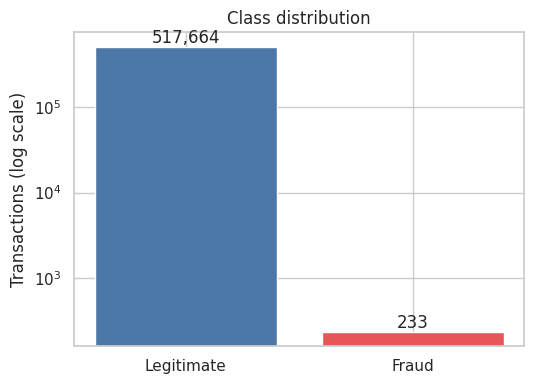

In [16]:
counts = df["isFraud"].value_counts().sort_index()
fraud_rate = df["isFraud"].mean()
imbalance_ratio = counts[0] / counts[1]

print(f"Legitimate : {counts[0]:>10,}")
print(f"Fraud      : {counts[1]:>10,}")
print(f"Fraud rate : {fraud_rate:.4%}  (1 fraud per {imbalance_ratio:,.0f} legitimate)")
print(f"A model that always predicts 'legitimate' would score {1 - fraud_rate:.4%} accuracy.")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(["Legitimate", "Fraud"], counts.values, color=[C_LEGIT, C_FRAUD])
ax.set_yscale("log")
ax.set_ylabel("Transactions (log scale)")
ax.set_title("Class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 4. Data quality checks and the built-in `isFlaggedFraud` rule

In [17]:
checks = pd.Series({
    "negative amounts": int((df["amount"] < 0).sum()),
    "zero-amount transactions": int((df["amount"] == 0).sum()),
    "negative balances (any of 4 columns)": int((df[["oldbalanceOrg", "newbalanceOrig",
                                                     "oldbalanceDest", "newbalanceDest"]] < 0).any(axis=1).sum()),
    "sender balance = 0 before transaction": int((df["oldbalanceOrg"] == 0).sum()),
    "receiver balance = 0 before transaction": int((df["oldbalanceDest"] == 0).sum()),
    "sender balance = 0 after transaction": int((df["newbalanceOrig"] == 0).sum()),
})
checks.to_frame("rows")

,rows
negative amounts,0
zero-amount transactions,0
negative balances (any of 4 columns),0
sender balance = 0 before transaction,168111
receiver balance = 0 before transaction,210127
sender balance = 0 after transaction,283850


In [18]:
flag_table = pd.crosstab(df["isFlaggedFraud"], df["isFraud"], margins=True)
display(flag_table)
flag_recall = df.loc[df["isFraud"] == 1, "isFlaggedFraud"].mean()
print(f"The built-in rule flags {int(df['isFlaggedFraud'].sum()):,} transactions "
      f"and catches {flag_recall:.2%} of all fraud.")

isFraud,0.0000,1.0000,All
isFlaggedFraud,,,
0.0000,517664,233,517897
All,517664,233,517897


The built-in rule flags 0 transactions and catches 0.00% of all fraud.


The built-in rule is effectively useless as a detector (it catches a tiny share of fraud), which is the baseline a learned model has to beat. We drop `isFlaggedFraud` from the feature set because it is a downstream system output, not an input available at scoring time.

## 5. EDA by transaction type

In [19]:
by_type = (df.groupby("type", observed=True)
             .agg(transactions=("isFraud", "size"),
                  fraud=("isFraud", "sum"),
                  total_amount=("amount", "sum"))
             .assign(fraud_rate_pct=lambda t: t["fraud"] / t["transactions"] * 100)
             .sort_values("transactions", ascending=False))
by_type

,transactions,fraud,total_amount,fraud_rate_pct
type,,,,
CASH_OUT,188582,121.0000,"35,077,998,435.2800",0.0642
PAYMENT,170076,0.0000,"1,962,332,685.6700",0.0000
CASH_IN,113380,0.0000,"19,601,556,318.4200",0.0000
TRANSFER,42126,112.0000,"28,826,900,922.8600",0.2659
DEBIT,3734,0.0000,"24,207,990.2200",0.0000


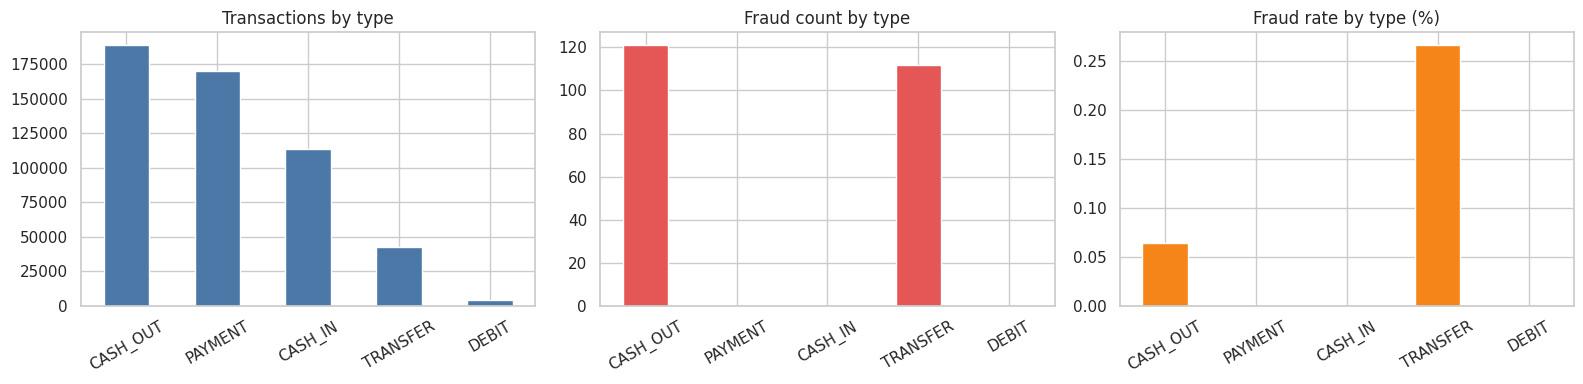

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
by_type["transactions"].plot.bar(ax=ax[0], color=C_LEGIT, title="Transactions by type")
by_type["fraud"].plot.bar(ax=ax[1], color=C_FRAUD, title="Fraud count by type")
by_type["fraud_rate_pct"].plot.bar(ax=ax[2], color="#f58518", title="Fraud rate by type (%)")
for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [21]:
fraud_types_seen = sorted(df.loc[df["isFraud"] == 1, "type"].astype(str).unique())
print("Transaction types that contain fraud:", fraud_types_seen)
print("\nFraud amount summary by type:")
display(df[df["isFraud"] == 1].groupby("type", observed=True)["amount"].describe())

Transaction types that contain fraud: ['CASH_OUT', 'TRANSFER']

Fraud amount summary by type:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
CASH_OUT,121.0000,"797,081.3832","1,644,459.9242",119.0000,"21,571.0000","143,032.0000","747,282.4000","10,000,000.0000"
TRANSFER,112.0000,"871,597.9517","1,701,199.9118",119.0000,"19,260.7550","135,752.8100","1,082,557.1300","10,000,000.0000"


Fraud is confined to a small set of transaction types (see the table above): money can only be stolen by moving it out of an account, i.e. `TRANSFER` and `CASH_OUT`. Every other type has zero fraud, so including those rows would only dilute the signal and add 'easy negatives'. Section 8 restricts the modelling data accordingly.

## 6. Amount analysis

For plotting we keep **all** fraud rows and a random sample of legitimate rows, and normalise each class's density separately so the shapes are comparable despite the 1:700 imbalance.

In [22]:
n_legit_plot = int(min(PLOT_SAMPLE, (df["isFraud"] == 0).sum()))
plot_df = pd.concat([
    df[df["isFraud"] == 1],
    df[df["isFraud"] == 0].sample(n_legit_plot, random_state=RANDOM_STATE),
])
plot_df["log10_amount"] = np.log10(plot_df["amount"] + 1)
plot_df["class"] = plot_df["isFraud"].map({0: "Legitimate", 1: "Fraud"})
print(f"Plot frame: {len(plot_df):,} rows ({int(plot_df['isFraud'].sum()):,} fraud)")

Plot frame: 300,233 rows (233 fraud)


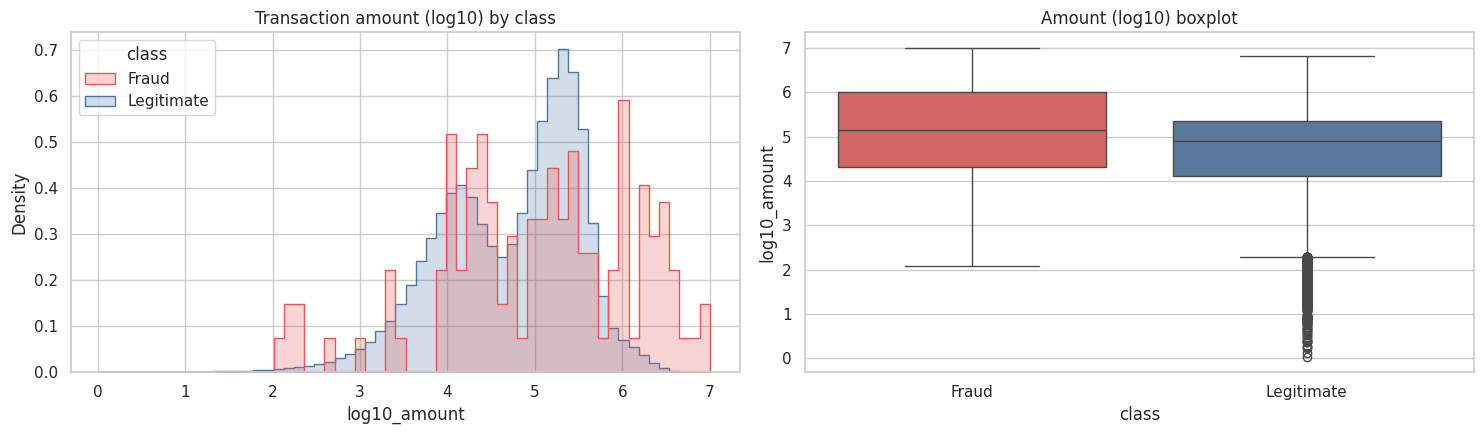

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=plot_df, x="log10_amount", hue="class", stat="density", common_norm=False,
             element="step", bins=60, palette={"Legitimate": C_LEGIT, "Fraud": C_FRAUD}, ax=ax[0])
ax[0].set_title("Transaction amount (log10) by class")
sns.boxplot(data=plot_df, x="class", y="log10_amount",
            palette={"Legitimate": C_LEGIT, "Fraud": C_FRAUD}, ax=ax[1])
ax[1].set_title("Amount (log10) boxplot")
plt.tight_layout()
plt.show()

In [24]:
print("Amount statistics by class:")
display(df.groupby("isFraud")["amount"].describe(percentiles=[.25, .5, .75, .95, .99]))

Amount statistics by class:


,count,mean,std,min,25%,50%,75%,95%,99%,max
isFraud,,,,,,,,,,
0.0000,"517,664.0000","164,776.3601","268,024.3744",0.1000,"13,206.3050","80,562.0350","220,603.8750","539,543.4805","1,379,602.2956","6,419,835.2700"
1.0000,233.0000,"832,900.5063","1,668,774.8228",119.0000,"20,128.0000","143,032.0000","994,453.2000","3,672,115.0900","10,000,000.0000","10,000,000.0000"


Fraudulent transactions are not small: they skew towards larger amounts. Amount alone cannot separate the classes though (the histograms overlap heavily), so we need features that describe how the transaction relates to the account balances.

## 7. Time analysis

`step` counts hours from the start of the simulation (743 steps, about 30 days). `step % 24` gives the hour of day.

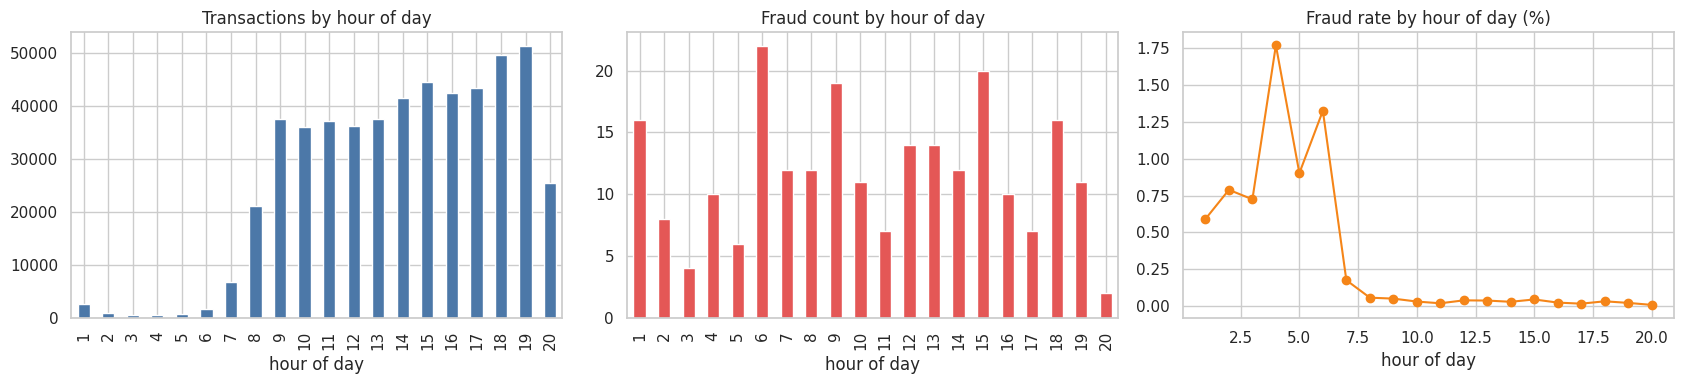

In [25]:
df["hour"] = df["step"] % 24
df["day"] = (df["step"] - 1) // 24 + 1

hourly = (df.groupby("hour")
            .agg(transactions=("isFraud", "size"), fraud=("isFraud", "sum"))
            .assign(fraud_rate_pct=lambda t: t["fraud"] / t["transactions"] * 100))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
hourly["transactions"].plot.bar(ax=ax[0], color=C_LEGIT, title="Transactions by hour of day")
hourly["fraud"].plot.bar(ax=ax[1], color=C_FRAUD, title="Fraud count by hour of day")
hourly["fraud_rate_pct"].plot(ax=ax[2], marker="o", color="#f58518", title="Fraud rate by hour of day (%)")
for a in ax:
    a.set_xlabel("hour of day")
plt.tight_layout()
plt.show()

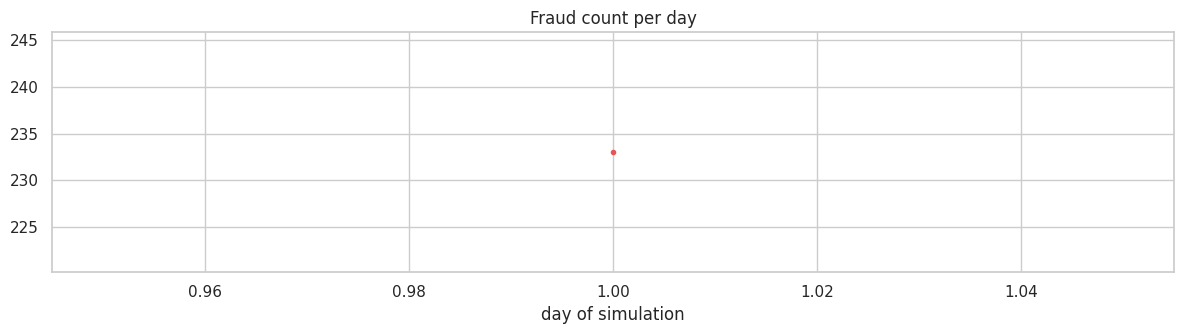

In [26]:
daily = (df.groupby("day")
           .agg(transactions=("isFraud", "size"), fraud=("isFraud", "sum"))
           .assign(fraud_rate_pct=lambda t: t["fraud"] / t["transactions"] * 100))
fig, ax = plt.subplots(figsize=(12, 3.5))
daily["fraud"].plot(ax=ax, color=C_FRAUD, marker=".")
ax.set_title("Fraud count per day")
ax.set_xlabel("day of simulation")
plt.tight_layout()
plt.show()

Legitimate volume follows a daily cycle while fraud is spread much more evenly across the day, so the fraud **rate** is highest in the low-volume hours. Time-of-day is therefore a plausible signal, but a real scoring service would need the transaction timestamp as an input. To keep the deployed app simple (the user types the transaction fields), the model uses transaction and balance features only; `hour` is listed as a possible extension at the end.

## 8. Restricting to `TRANSFER` and `CASH_OUT`

In [27]:
FRAUD_TYPES = ["TRANSFER", "CASH_OUT"]

data = df[df["type"].isin(FRAUD_TYPES)].copy()
data["type"] = data["type"].astype(str)
data = data.reset_index(drop=True)

kept_share = len(data) / len(df)
fraud_kept = data["isFraud"].sum() / df["isFraud"].sum()
print(f"Rows kept          : {len(data):,} ({kept_share:.1%} of all transactions)")
print(f"Fraud rows retained: {int(data['isFraud'].sum()):,} ({fraud_kept:.1%} of all fraud)")
print(f"Fraud rate in subset: {data['isFraud'].mean():.4%} (was {fraud_rate:.4%})")

Rows kept          : 230,708 (44.5% of all transactions)
Fraud rows retained: 233 (100.0% of all fraud)
Fraud rate in subset: 0.1010% (was 0.0450%)


We lose none of the fraud and remove roughly 56% of the rows, so the imbalance becomes less extreme while the modelling problem stays faithful to where fraud actually happens. In deployment, transactions of other types are routed around the model (they cannot be fraudulent under this data's rules).

## 9. Feature engineering

Raw balances are noisy; what matters is whether the transaction **makes sense** given the balances.

| Feature | Definition | Intuition |
|---|---|---|
| `balanceDiffOrig` | `oldbalanceOrg - newbalanceOrig` | how much left the sender account |
| `balanceDiffDest` | `newbalanceDest - oldbalanceDest` | how much arrived at the receiver |
| `errorBalanceOrig` | `newbalanceOrig + amount - oldbalanceOrg` | 0 if the sender's books reconcile |
| `errorBalanceDest` | `oldbalanceDest + amount - newbalanceDest` | 0 if the receiver's books reconcile |
| `origEmptied` | sender had money and ends at exactly 0 | fraud typically drains the account |
| `destUntouched` | receiver balance is 0 before and after a positive amount | money 'disappears' into an account that never shows it |
| `amountToBalance` | `amount / (oldbalanceOrg + 1)`, clipped to [0, 10] | what share of the balance is moved |

**Note on linear models:** the first four features are exact linear combinations of the raw columns, so they add no new information to a *linear* model like Logistic Regression (they can help tree models and make the reconciliation idea explicit). The three flag/ratio features are non-linear and are where a linear model gets genuinely new signal. Section 20 measures this with an ablation instead of assuming it.

In [28]:
RAW_NUM = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
ENG_NUM = ["balanceDiffOrig", "balanceDiffDest", "errorBalanceOrig", "errorBalanceDest",
           "origEmptied", "destUntouched", "amountToBalance"]
NUM_FEATURES = RAW_NUM + ENG_NUM
CAT_FEATURES = ["type"]
TARGET = "isFraud"


def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Add engineered features. The Streamlit app re-implements exactly this logic."""
    out = frame.copy()
    out["balanceDiffOrig"] = out["oldbalanceOrg"] - out["newbalanceOrig"]
    out["balanceDiffDest"] = out["newbalanceDest"] - out["oldbalanceDest"]
    out["errorBalanceOrig"] = out["newbalanceOrig"] + out["amount"] - out["oldbalanceOrg"]
    out["errorBalanceDest"] = out["oldbalanceDest"] + out["amount"] - out["newbalanceDest"]
    out["origEmptied"] = ((out["oldbalanceOrg"] > 0) & (out["newbalanceOrig"] == 0)).astype(int)
    out["destUntouched"] = ((out["oldbalanceDest"] == 0) & (out["newbalanceDest"] == 0)
                            & (out["amount"] > 0)).astype(int)
    out["amountToBalance"] = np.clip(out["amount"] / (out["oldbalanceOrg"] + 1), 0, 10)
    return out


data_fe = add_features(data)
data_fe[RAW_NUM + ENG_NUM + [TARGET]].head(10)

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,balanceDiffOrig,balanceDiffDest,errorBalanceOrig,errorBalanceDest,origEmptied,destUntouched,amountToBalance,isFraud
0,181.0000,181.0000,0.0000,0.0000,0.0000,181.0000,0.0000,0.0000,181.0000,1,1,0.9945,1.0000
1,181.0000,181.0000,0.0000,"21,182.0000",0.0000,181.0000,"-21,182.0000",0.0000,"21,363.0000",1,0,0.9945,1.0000
2,"229,133.9400","15,325.0000",0.0000,"5,083.0000","51,513.4400","15,325.0000","46,430.4400","213,808.9400","182,703.5000",1,0,10.0000,0.0000
3,"215,310.3000",705.0000,0.0000,"22,425.0000",0.0000,705.0000,"-22,425.0000","214,605.3000","237,735.3000",1,0,10.0000,0.0000
4,"311,685.8900","10,835.0000",0.0000,"6,267.0000","2,719,172.8900","10,835.0000","2,712,905.8900","300,850.8900","-2,401,220.0000",1,0,10.0000,0.0000
5,"110,414.7100","26,845.4100",0.0000,"288,800.0000","2,415.1600","26,845.4100","-286,384.8400","83,569.3000","396,799.5500",1,0,4.1128,0.0000
6,"56,953.9000","1,942.0200",0.0000,"70,253.0000","64,106.1800","1,942.0200","-6,146.8200","55,011.8800","63,100.7200",1,0,10.0000,0.0000
7,"5,346.8900",0.0000,0.0000,"652,637.0000","6,453,430.9100",0.0000,"5,800,793.9100","5,346.8900","-5,795,447.0200",0,0,10.0000,0.0000
8,"23,261.3000","20,411.5300",0.0000,"25,742.0000",0.0000,"20,411.5300","-25,742.0000","2,849.7700","49,003.3000",1,0,1.1396,0.0000
9,"62,610.8000","79,114.0000","16,503.2000",517.0000,"8,383.2900","62,610.8000","7,866.2900",0.0000,"54,744.5100",0,0,0.7914,0.0000


## 10. Behaviour of the engineered features and correlation analysis

In [29]:
flag_rates = (data_fe.groupby(["type", TARGET])[["origEmptied", "destUntouched"]]
                     .mean().mul(100).round(2).unstack(TARGET))
flag_rates.columns = [f"{feat} % ({'fraud' if lab else 'legit'})" for feat, lab in flag_rates.columns]
print("Share of transactions (%) where each flag is set, by type and class:")
flag_rates

Share of transactions (%) where each flag is set, by type and class:


,origEmptied % (legit),origEmptied % (fraud),destUntouched % (legit),destUntouched % (fraud)
type,,,,
CASH_OUT,40.6200,90.9100,0.4100,0.0000
TRANSFER,43.6700,95.5400,0.1500,83.9300


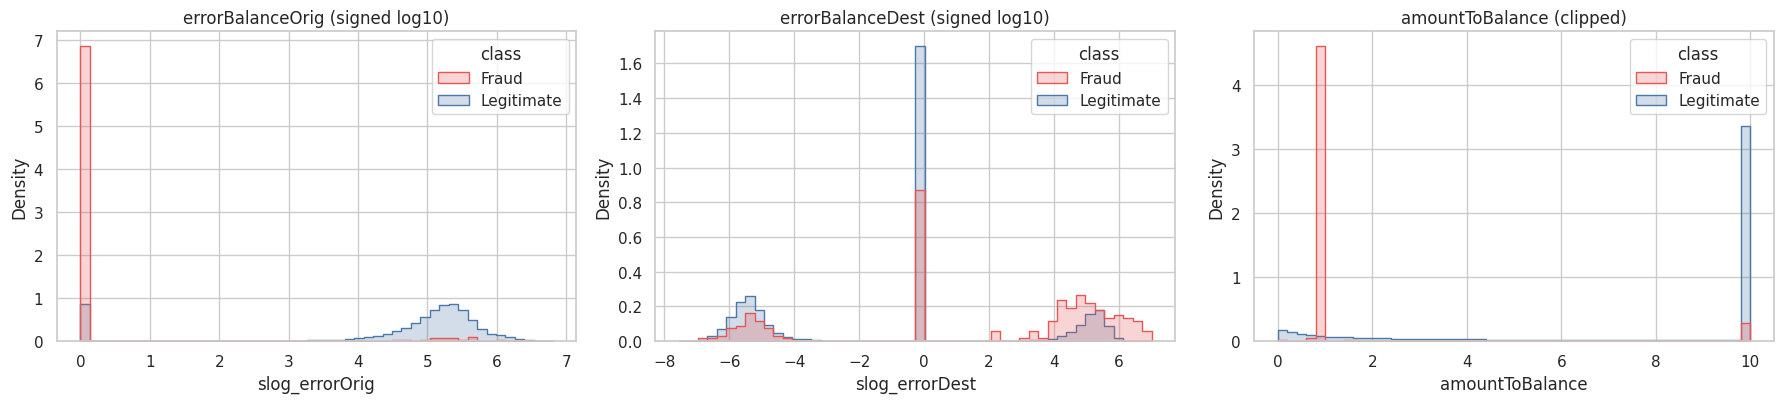

In [30]:
def slog(s):
    """Signed log10, to plot heavy-tailed values that can be negative."""
    return np.sign(s) * np.log10(1 + np.abs(s))


fe_plot = pd.concat([
    data_fe[data_fe[TARGET] == 1],
    data_fe[data_fe[TARGET] == 0].sample(min(200_000, int((data_fe[TARGET] == 0).sum())),
                                          random_state=RANDOM_STATE),
]).copy()
fe_plot["class"] = fe_plot[TARGET].map({0: "Legitimate", 1: "Fraud"})
fe_plot["slog_errorOrig"] = slog(fe_plot["errorBalanceOrig"])
fe_plot["slog_errorDest"] = slog(fe_plot["errorBalanceDest"])

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
pal = {"Legitimate": C_LEGIT, "Fraud": C_FRAUD}
for a, col, title in zip(ax, ["slog_errorOrig", "slog_errorDest", "amountToBalance"],
                         ["errorBalanceOrig (signed log10)", "errorBalanceDest (signed log10)",
                          "amountToBalance (clipped)"]):
    sns.histplot(data=fe_plot, x=col, hue="class", stat="density", common_norm=False,
                 element="step", bins=50, palette=pal, ax=a)
    a.set_title(title)
plt.tight_layout()
plt.show()

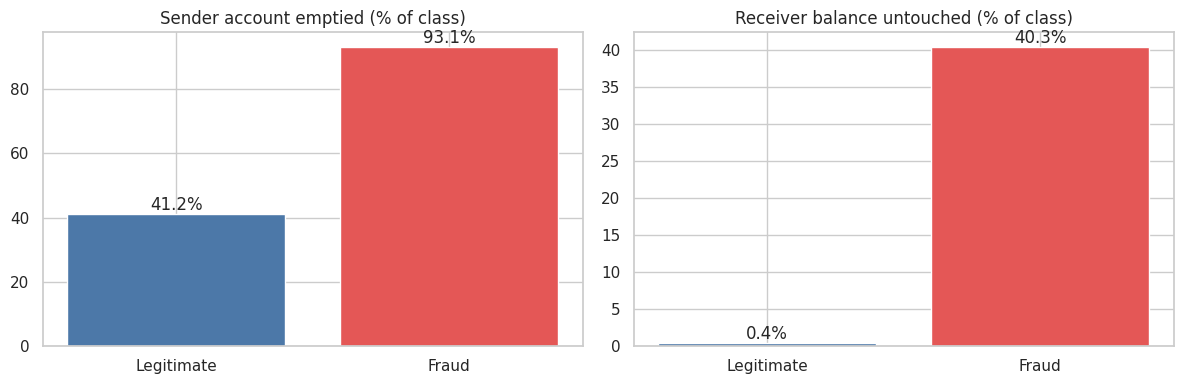

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, flag, title in zip(ax, ["origEmptied", "destUntouched"],
                          ["Sender account emptied", "Receiver balance untouched"]):
    rates = data_fe.groupby(TARGET)[flag].mean().mul(100)
    a.bar(["Legitimate", "Fraud"], rates.values, color=[C_LEGIT, C_FRAUD])
    a.set_title(f"{title} (% of class)")
    for i, v in enumerate(rates.values):
        a.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

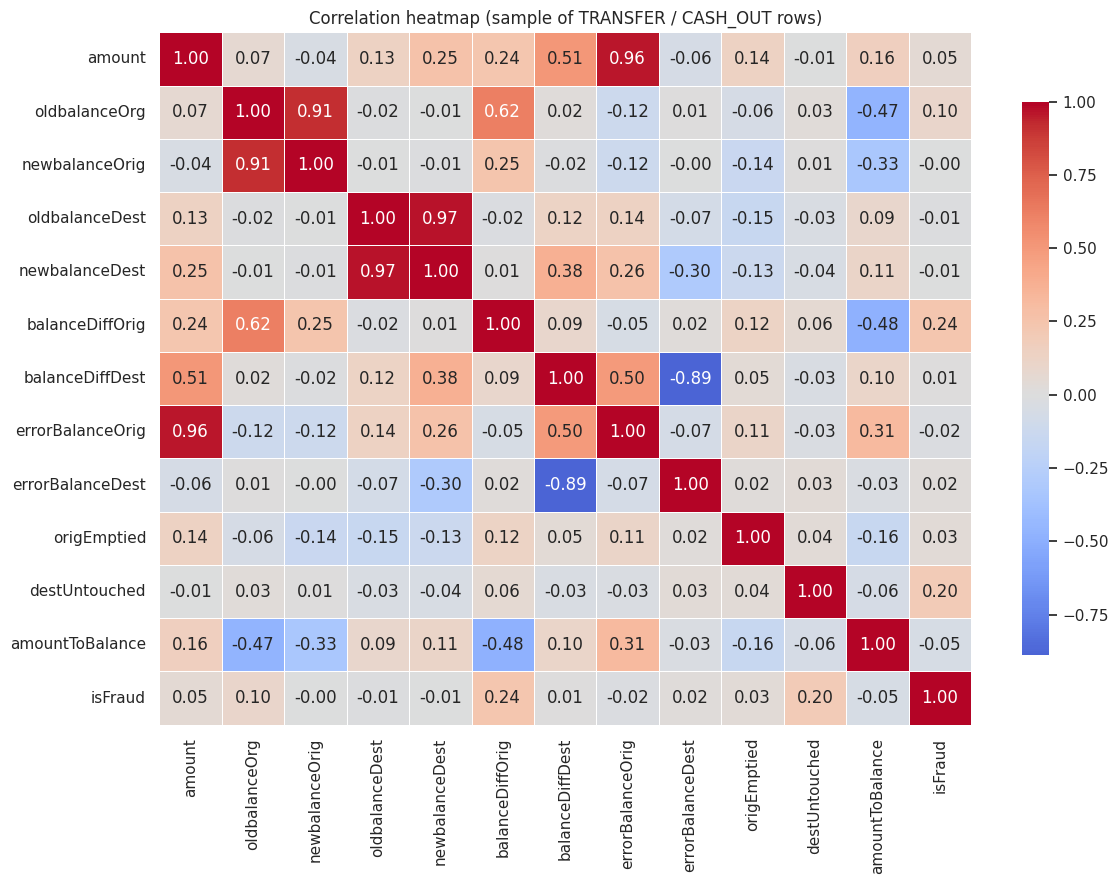

In [32]:
corr_sample = data_fe.sample(min(500_000, len(data_fe)), random_state=RANDOM_STATE)
corr = corr_sample[RAW_NUM + ENG_NUM + [TARGET]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.4,
            cbar_kws={"shrink": 0.8})
plt.title("Correlation heatmap (sample of TRANSFER / CASH_OUT rows)")
plt.tight_layout()
plt.show()

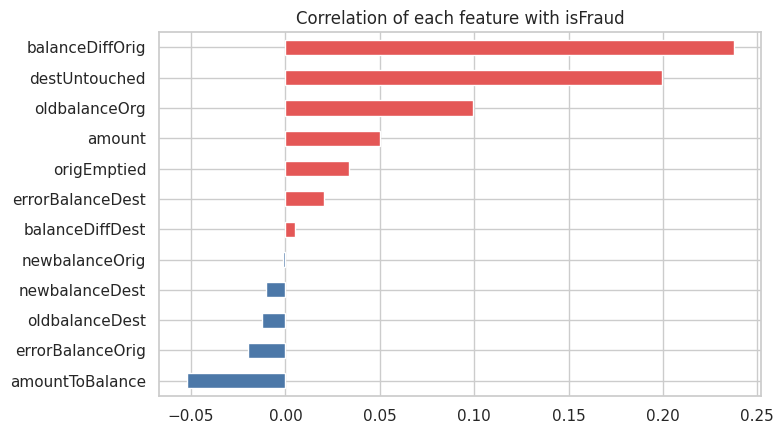

,corr with isFraud
balanceDiffOrig,0.2377
destUntouched,0.1997
oldbalanceOrg,0.0992
amountToBalance,-0.0523
amount,0.0499
origEmptied,0.0335
errorBalanceDest,0.0203
errorBalanceOrig,-0.0199
oldbalanceDest,-0.0124
newbalanceDest,-0.0102


In [33]:
target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
target_corr.sort_values().plot.barh(ax=ax, color=[C_FRAUD if v > 0 else C_LEGIT for v in target_corr.sort_values()])
ax.set_title("Correlation of each feature with isFraud")
plt.tight_layout()
plt.show()
target_corr.to_frame("corr with isFraud")

The heatmap shows strong collinearity among the balance columns (as expected, a new balance is almost the old balance plus or minus the amount). This does not hurt predictions with regularised Logistic Regression, but it means **individual coefficients should be read with care** (Section 18).

## 11. Train / validation / test split

* **Stratified** so the 0.3% fraud share is identical in every split.
* The **test set is touched once**, at the end, for reporting.
* A **validation set** is carved out of the training data to pick the decision threshold, so we never tune on test data.

In [34]:
print(data_fe[[TARGET] + NUM_FEATURES + CAT_FEATURES].isna().sum())

data_fe = data_fe.dropna(subset=[TARGET] + NUM_FEATURES + CAT_FEATURES).reset_index(drop=True)
data_fe[TARGET] = data_fe[TARGET].astype(int)
print(f"Rows after dropping NaN: {len(data_fe):,}")

isFraud             1
amount              0
oldbalanceOrg       0
newbalanceOrig      0
oldbalanceDest      0
newbalanceDest      1
balanceDiffOrig     0
balanceDiffDest     1
errorBalanceOrig    0
errorBalanceDest    1
origEmptied         0
destUntouched       0
amountToBalance     0
type                0
dtype: int64
Rows after dropping NaN: 230,707


In [35]:
X = data_fe[NUM_FEATURES + CAT_FEATURES]
y = data_fe[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=VAL_SIZE, stratify=y_train, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "rows": [len(y_fit), len(y_val), len(y_train), len(y_test)],
    "fraud": [int(y_fit.sum()), int(y_val.sum()), int(y_train.sum()), int(y_test.sum())],
}, index=["fit (train minus val)", "validation", "train (total)", "test"])
split_summary["fraud_rate_%"] = split_summary["fraud"] / split_summary["rows"] * 100
split_summary

,rows,fraud,fraud_rate_%
fit (train minus val),138423,139,0.1004
validation,46142,47,0.1019
train (total),184565,186,0.1008
test,46142,47,0.1019


## 12. Preprocessing pipeline

`StandardScaler` for numeric features (essential for Logistic Regression: balances span many orders of magnitude) and `OneHotEncoder` for `type`, combined with a `ColumnTransformer` and wrapped in a single `Pipeline` so training and inference apply identical transformations. `handle_unknown="ignore"` keeps the service from crashing on unseen categories.

In [36]:
def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])


def make_lr(num_cols=NUM_FEATURES, cat_cols=CAT_FEATURES, class_weight="balanced"):
    return Pipeline([
        ("prep", make_preprocessor(num_cols, cat_cols)),
        ("clf", LogisticRegression(class_weight=class_weight, max_iter=1000)),
    ])


def evaluate(name, y_true, proba, threshold=0.5):
    """Return a dict of imbalance-aware metrics at a given decision threshold."""
    y_true = np.asarray(y_true)
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "model": name, "threshold": threshold,
        "accuracy": (tp + tn) / len(y_true),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "mcc": matthews_corrcoef(y_true, pred),
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }


results = []   # every model evaluated on the TEST set gets appended here
print("Preprocessing pipeline ready.")
make_preprocessor(NUM_FEATURES, CAT_FEATURES)

Preprocessing pipeline ready.


ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['amount', 'oldbalanceOrg', 'newbalanceOrig',
                                  'oldbalanceDest', 'newbalanceDest',
                                  'balanceDiffOrig', 'balanceDiffDest',
                                  'errorBalanceOrig', 'errorBalanceDest',
                                  'origEmptied', 'destUntouched',
                                  'amountToBalance']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['type'])])

## 13. Baselines

Two reference points tell us whether the main model is actually learning something:

1. **Majority-class dummy**: always predicts 'legitimate'. High accuracy, zero usefulness.
2. **Unweighted Logistic Regression**: shows what class weighting changes.

In [37]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_proba = dummy.predict_proba(X_test)[:, 1]
res_dummy = evaluate("Majority-class dummy", y_test, dummy_proba)
results.append(res_dummy)
print(f"Dummy accuracy: {res_dummy['accuracy']:.4%} | recall: {res_dummy['recall']:.2%} "
      f"| fraud caught: {res_dummy['tp']} of {res_dummy['tp'] + res_dummy['fn']}")

Dummy accuracy: 99.8981% | recall: 0.00% | fraud caught: 0 of 47


In [38]:
t0 = time.time()
lr_plain = make_lr(class_weight=None).fit(X_train, y_train)
plain_proba = lr_plain.predict_proba(X_test)[:, 1]
res_plain = evaluate("LogReg (no class weights)", y_test, plain_proba)
results.append(res_plain)
print(f"Fit in {time.time() - t0:.0f}s")
pd.DataFrame([res_dummy, res_plain]).set_index("model")[["accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc"]]

Fit in 1s


,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Majority-class dummy,0.9990,0.0000,0.0000,0.0000,0.0010,0.5000
LogReg (no class weights),0.9993,0.9000,0.3830,0.5373,0.5474,0.9378


Without class weights the model optimises overall log-loss, which the legitimate majority dominates, so it tends to be conservative about raising fraud alerts. Class weights re-balance the loss so each fraud example counts as much as roughly `n_legit / n_fraud` legitimate ones.

## 14. Logistic Regression with class weights (main model)

In [39]:
t0 = time.time()
lr_pipe = make_lr(class_weight="balanced").fit(X_train, y_train)
proba_lr = lr_pipe.predict_proba(X_test)[:, 1]
print(f"Fit in {time.time() - t0:.0f}s")

res_lr_05 = evaluate("LogReg balanced @0.5", y_test, proba_lr, 0.5)
results.append(res_lr_05)

pred_lr = (proba_lr >= 0.5).astype(int)
print(classification_report(y_test, pred_lr, target_names=["Legitimate", "Fraud"], digits=4))

Fit in 1s
              precision    recall  f1-score   support

  Legitimate     0.9999    0.8563    0.9225     46095
       Fraud     0.0063    0.8936    0.0125        47

    accuracy                         0.8563     46142
   macro avg     0.5031    0.8750    0.4675     46142
weighted avg     0.9989    0.8563    0.9216     46142



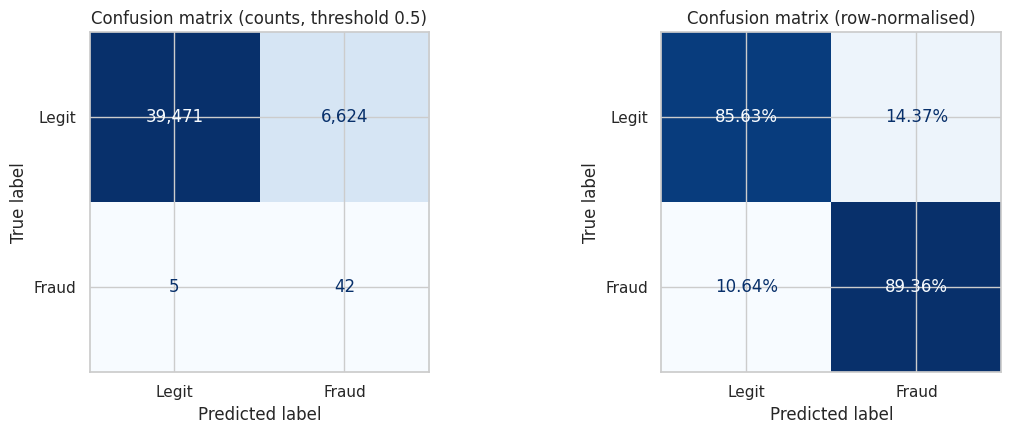

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=["Legit", "Fraud"],
                                        ax=ax[0], colorbar=False, values_format=",d", cmap="Blues")
ax[0].set_title("Confusion matrix (counts, threshold 0.5)")
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=["Legit", "Fraud"],
                                        normalize="true", ax=ax[1], colorbar=False,
                                        values_format=".2%", cmap="Blues")
ax[1].set_title("Confusion matrix (row-normalised)")
plt.tight_layout()
plt.show()

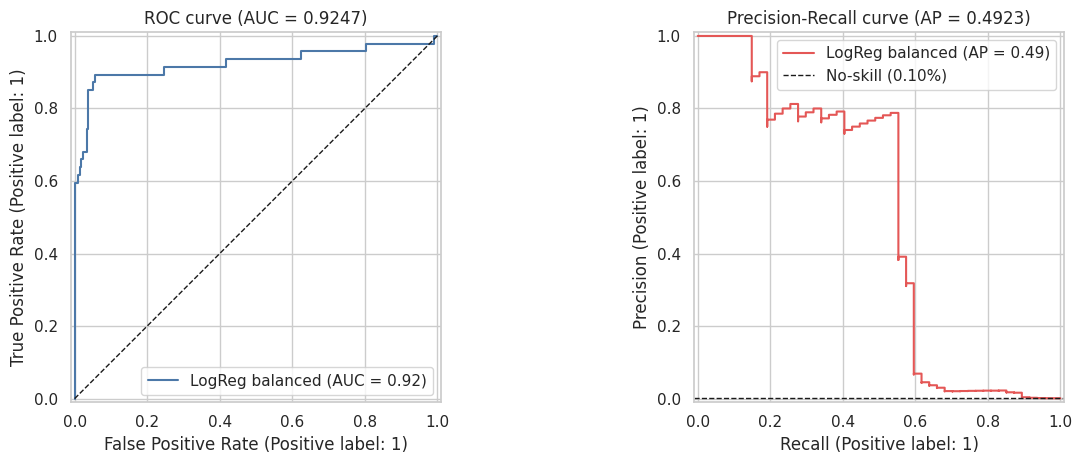

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
RocCurveDisplay.from_predictions(y_test, proba_lr, ax=ax[0], name="LogReg balanced", color=C_LEGIT)
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_title(f"ROC curve (AUC = {res_lr_05['roc_auc']:.4f})")
PrecisionRecallDisplay.from_predictions(y_test, proba_lr, ax=ax[1], name="LogReg balanced", color=C_FRAUD)
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"No-skill ({y_test.mean():.2%})")
ax[1].legend()
ax[1].set_title(f"Precision-Recall curve (AP = {res_lr_05['pr_auc']:.4f})")
plt.tight_layout()
plt.show()

**Reading the numbers.** At the default 0.5 threshold, class weighting buys high *recall* at the cost of *precision* (more false alarms), which is the usual trade-off. ROC-AUC looks flattering on imbalanced data because the huge number of true negatives keeps the false-positive *rate* tiny; PR-AUC and the precision/recall pair are the honest metrics. Next we choose the operating point deliberately instead of accepting 0.5.

## 15. Threshold selection on validation data

A class-weighted model's probabilities are shifted upwards, so 0.5 is not a meaningful cut-off. We:

1. fit a model on the **fit** split only,
2. find the threshold that maximises **F1 on the validation split**,
3. apply that threshold to the final model (trained on the full training set) and report on **test**.

In [42]:
def best_f1_threshold(y_true, proba):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i]), prec[:-1], rec[:-1], thr, f1


lr_val_model = make_lr().fit(X_fit, y_fit)
val_proba = lr_val_model.predict_proba(X_val)[:, 1]
tuned_threshold, val_best_f1, p_curve, r_curve, t_curve, f1_curve = best_f1_threshold(y_val, val_proba)
print(f"Best validation F1 = {val_best_f1:.4f} at threshold {tuned_threshold:.4f}")

Best validation F1 = 0.6234 at threshold 0.9878


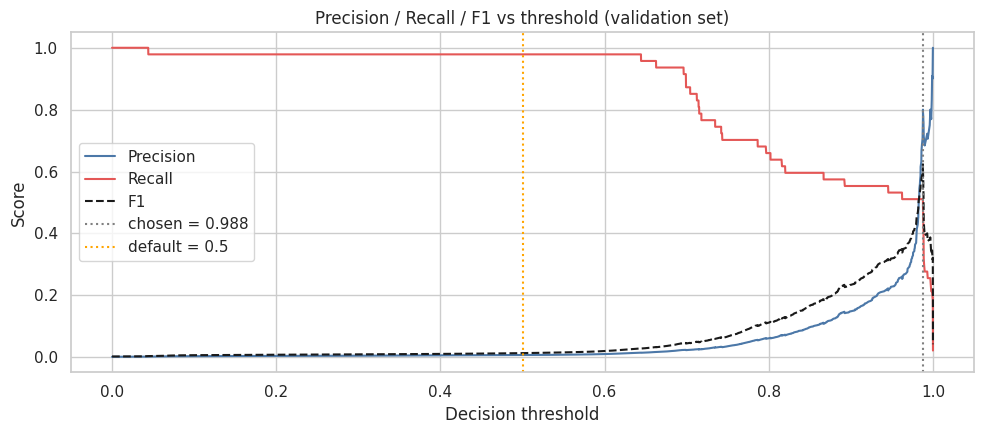

In [43]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t_curve, p_curve, label="Precision", color=C_LEGIT)
ax.plot(t_curve, r_curve, label="Recall", color=C_FRAUD)
ax.plot(t_curve, f1_curve, label="F1", color="k", ls="--")
ax.axvline(tuned_threshold, color="grey", ls=":", label=f"chosen = {tuned_threshold:.3f}")
ax.axvline(0.5, color="orange", ls=":", label="default = 0.5")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 vs threshold (validation set)")
ax.legend()
plt.tight_layout()
plt.show()

In [44]:
res_lr_tuned = evaluate("LogReg balanced @tuned", y_test, proba_lr, tuned_threshold)
results.append(res_lr_tuned)

compare = pd.DataFrame([res_lr_05, res_lr_tuned]).set_index("model")
compare[["threshold", "precision", "recall", "f1", "f2", "mcc", "tp", "fp", "fn"]]

,threshold,precision,recall,f1,f2,mcc,tp,fp,fn
model,,,,,,,,,
LogReg balanced @0.5,0.5000,0.0063,0.8936,0.0125,0.0306,0.0680,42,6624,5
LogReg balanced @tuned,0.9878,0.7647,0.5532,0.6420,0.5856,0.6501,26,8,21


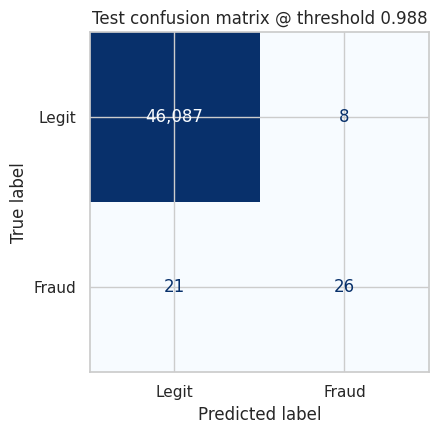

              precision    recall  f1-score   support

  Legitimate     0.9995    0.9998    0.9997     46095
       Fraud     0.7647    0.5532    0.6420        47

    accuracy                         0.9994     46142
   macro avg     0.8821    0.7765    0.8208     46142
weighted avg     0.9993    0.9994    0.9993     46142



In [45]:
pred_tuned = (proba_lr >= tuned_threshold).astype(int)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_tuned, display_labels=["Legit", "Fraud"],
                                        ax=ax, colorbar=False, values_format=",d", cmap="Blues")
ax.set_title(f"Test confusion matrix @ threshold {tuned_threshold:.3f}")
plt.tight_layout()
plt.show()
print(classification_report(y_test, pred_tuned, target_names=["Legitimate", "Fraud"], digits=4))

Moving the threshold trades false alarms against missed fraud; whichever point is chosen should come from the business cost of each error, which is what the next section quantifies. (F1 weights both errors equally; `f2` above weights recall twice as much, which is closer to reality when a missed fraud costs more than a manual review.)

## 16. Business impact of the model

Model metrics are only meaningful if they translate into money and workload. All currency amounts below are PaySim's simulated units.

In [46]:
def business_impact(y_true, amounts, pred):
    y_true, amounts, pred = np.asarray(y_true), np.asarray(amounts), np.asarray(pred)
    fraud_total = amounts[y_true == 1].sum()
    caught = amounts[(y_true == 1) & (pred == 1)].sum()
    missed = amounts[(y_true == 1) & (pred == 0)].sum()
    fa_mask = (y_true == 0) & (pred == 1)
    return {
        "fraud value in test set": fraud_total,
        "fraud value stopped": caught,
        "fraud value missed": missed,
        "value recall %": caught / fraud_total * 100,
        "false alarms (count)": int(fa_mask.sum()),
        "legit value held for review": amounts[fa_mask].sum(),
        "alerts per true fraud": (pred.sum() / max((y_true & pred).sum(), 1)),
        "% of all transactions alerted": pred.mean() * 100,
    }


amounts_test = X_test["amount"].values
impact = pd.DataFrame({
    "No model": business_impact(y_test, amounts_test, np.zeros(len(y_test), dtype=int)),
    "LogReg @0.5": business_impact(y_test, amounts_test, (proba_lr >= 0.5).astype(int)),
    f"LogReg @{tuned_threshold:.3f}": business_impact(y_test, amounts_test, pred_tuned),
})
impact.style.format("{:,.2f}")

,No model,LogReg @0.5,LogReg @0.988
fraud value in test set,"38,378,211.28","38,378,211.28","38,378,211.28"
fraud value stopped,0.00,"36,645,532.17","33,453,421.27"
fraud value missed,"38,378,211.28","1,732,679.11","4,924,790.01"
value recall %,0.00,95.49,87.17
false alarms (count),0.00,"6,624.00",8.00
legit value held for review,0.00,"1,423,182,193.68","10,473,449.09"
alerts per true fraud,0.00,158.71,1.31
% of all transactions alerted,0.00,14.45,0.07


,review budget (% of txns),fraud caught (%)
0,0.1000,55.3191
1,0.2500,59.5745
2,0.5000,59.5745
3,1.0000,61.7021
4,2.0000,65.9574
5,5.0000,85.1064


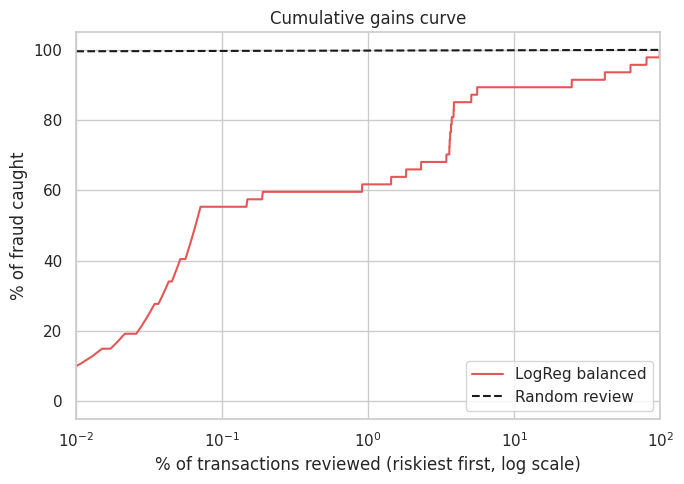

In [47]:
# Cumulative gains: if analysts can only review the top-k% riskiest transactions,
# what share of all fraud do they catch?
order = np.argsort(-proba_lr)
y_sorted = np.asarray(y_test)[order]
cum_fraud = np.cumsum(y_sorted) / y_sorted.sum()
frac_reviewed = np.arange(1, len(y_sorted) + 1) / len(y_sorted)

budgets = [0.001, 0.0025, 0.005, 0.01, 0.02, 0.05]
gain_table = pd.DataFrame({
    "review budget (% of txns)": [b * 100 for b in budgets],
    "fraud caught (%)": [cum_fraud[int(b * len(y_sorted)) - 1] * 100 for b in budgets],
})
display(gain_table)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(frac_reviewed * 100, cum_fraud * 100, color=C_FRAUD, label="LogReg balanced")
ax.plot([0, 100], [0, 100], "k--", label="Random review")
ax.set_xscale("log")
ax.set_xlim(0.01, 100)
ax.set_xlabel("% of transactions reviewed (riskiest first, log scale)")
ax.set_ylabel("% of fraud caught")
ax.set_title("Cumulative gains curve")
ax.legend()
plt.tight_layout()
plt.show()

Two business-facing takeaways to quote: **(a)** the share of fraud *value* stopped (value recall) and **(b)** the review workload needed to get it (alerts per true fraud / % of transactions alerted). The gains table shows how much fraud a fixed review budget captures, which is how a fraud-ops team would actually size the system.

## 17. Cross-validation stability

A single train/test split can be lucky. Stratified 5-fold cross-validation on a subsample of the training data shows how much the metrics move across folds (default 0.5 threshold for recall/precision).

In [48]:
cv_idx = X_train.sample(min(CV_ROWS, len(X_train)), random_state=RANDOM_STATE).index
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

t0 = time.time()
cv_res = cross_validate(
    make_lr(), X_train.loc[cv_idx], y_train.loc[cv_idx], cv=cv, n_jobs=-1,
    scoring={"recall": "recall", "precision": "precision",
             "pr_auc": "average_precision", "roc_auc": "roc_auc"})
print(f"CV finished in {time.time() - t0:.0f}s on {len(cv_idx):,} rows")

cv_table = pd.DataFrame({k.replace("test_", ""): v for k, v in cv_res.items() if k.startswith("test_")})
cv_summary = cv_table.agg(["mean", "std"]).T
display(cv_table.round(4))
cv_summary

CV finished in 4s on 184,565 rows


,recall,precision,pr_auc,roc_auc
0,0.8919,0.0098,0.5234,0.9018
1,0.9730,0.0066,0.3269,0.9547
2,0.8919,0.0065,0.3602,0.9275
3,0.9459,0.0063,0.5357,0.9539
4,0.9211,0.0066,0.4690,0.9634


,mean,std
recall,0.9248,0.0352
precision,0.0072,0.0015
pr_auc,0.4430,0.0950
roc_auc,0.9403,0.0253


## 18. Model interpretation (coefficients)

Logistic Regression is interpretable: each coefficient is the change in log-odds of fraud per one standard deviation of the feature (inputs are standardised). `exp(coef)` is the corresponding odds ratio. Because several features are collinear, treat individual signs and sizes as indicative, not causal.

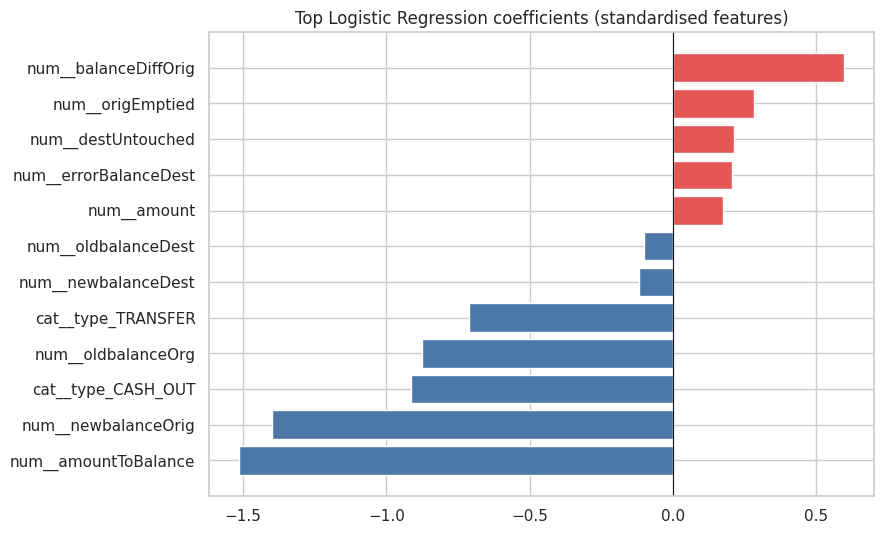

,coef,odds_ratio
num__amountToBalance,-1.5146,0.2199
num__newbalanceOrig,-1.3987,0.2469
cat__type_CASH_OUT,-0.9141,0.4009
num__oldbalanceOrg,-0.8755,0.4167
cat__type_TRANSFER,-0.7131,0.4901
num__balanceDiffOrig,0.5961,1.8151
num__origEmptied,0.2836,1.3280
num__destUntouched,0.2140,1.2387
num__errorBalanceDest,0.2058,1.2285
num__amount,0.1738,1.1898


In [49]:
feature_names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=feature_names)
coef_table = pd.DataFrame({"coef": coefs, "odds_ratio": np.exp(coefs)}).sort_values("coef", key=np.abs, ascending=False)

top = coef_table.head(12).sort_values("coef")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top["coef"], color=[C_FRAUD if v > 0 else C_LEGIT for v in top["coef"]])
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Top Logistic Regression coefficients (standardised features)")
plt.tight_layout()
plt.show()
coef_table

## 19. Comparison with Random Forest and XGBoost

Tree ensembles capture non-linear interactions automatically. We use them as a reference to see how much headroom the interpretable linear model leaves. Random Forest is trained on a subsample of the training set for speed; XGBoost uses the full training set with `scale_pos_weight` for the imbalance.

In [50]:
rf_idx = X_train.sample(min(RF_TRAIN_ROWS, len(X_train)), random_state=RANDOM_STATE).index
rf_pipe = Pipeline([
    ("prep", make_preprocessor(NUM_FEATURES, CAT_FEATURES)),
    ("clf", RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=5,
                                   class_weight="balanced_subsample", n_jobs=-1,
                                   random_state=RANDOM_STATE)),
])
t0 = time.time()
rf_pipe.fit(X_train.loc[rf_idx], y_train.loc[rf_idx])
rf_proba = rf_pipe.predict_proba(X_test)[:, 1]
print(f"Random Forest fit on {len(rf_idx):,} rows in {time.time() - t0:.0f}s")
res_rf = evaluate("Random Forest @0.5", y_test, rf_proba, 0.5)
results.append(res_rf)

Random Forest fit on 184,565 rows in 29s


In [51]:
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
xgb_pipe = Pipeline([
    ("prep", make_preprocessor(NUM_FEATURES, CAT_FEATURES)),
    ("clf", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                          colsample_bytree=0.8, scale_pos_weight=neg / pos,
                          tree_method="hist", eval_metric="aucpr", n_jobs=-1,
                          random_state=RANDOM_STATE)),
])
t0 = time.time()
xgb_pipe.fit(X_train, y_train)
xgb_proba = xgb_pipe.predict_proba(X_test)[:, 1]
print(f"XGBoost fit on {len(X_train):,} rows in {time.time() - t0:.0f}s")
res_xgb = evaluate("XGBoost @0.5", y_test, xgb_proba, 0.5)
results.append(res_xgb)

XGBoost fit on 184,565 rows in 5s


In [52]:
model_table = (pd.DataFrame(results).set_index("model")
               [["threshold", "precision", "recall", "f1", "mcc", "pr_auc", "roc_auc", "tp", "fp", "fn"]]
               .sort_values("pr_auc", ascending=False))
model_table

,threshold,precision,recall,f1,mcc,pr_auc,roc_auc,tp,fp,fn
model,,,,,,,,,,
Random Forest @0.5,0.5000,1.0000,0.8936,0.9438,0.9453,0.8968,0.9605,42,0,5
XGBoost @0.5,0.5000,0.8235,0.8936,0.8571,0.8577,0.8713,0.9604,42,9,5
LogReg (no class weights),0.5000,0.9000,0.3830,0.5373,0.5869,0.5474,0.9378,18,2,29
LogReg balanced @tuned,0.9878,0.7647,0.5532,0.6420,0.6501,0.4923,0.9247,26,8,21
LogReg balanced @0.5,0.5000,0.0063,0.8936,0.0125,0.0680,0.4923,0.9247,42,6624,5
Majority-class dummy,0.5000,0.0000,0.0000,0.0000,0.0000,0.0010,0.5000,0,0,47


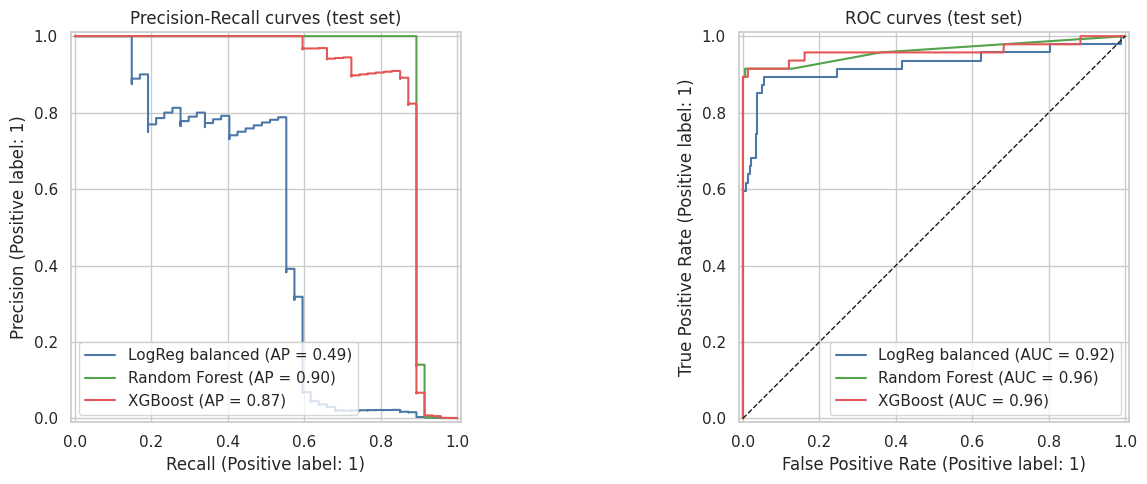

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, proba, color in [("LogReg balanced", proba_lr, C_LEGIT),
                           ("Random Forest", rf_proba, "#54a24b"),
                           ("XGBoost", xgb_proba, C_FRAUD)]:
    PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[0], name=name, color=color)
    RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1], name=name, color=color)
ax[0].set_title("Precision-Recall curves (test set)")
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_title("ROC curves (test set)")
plt.tight_layout()
plt.show()

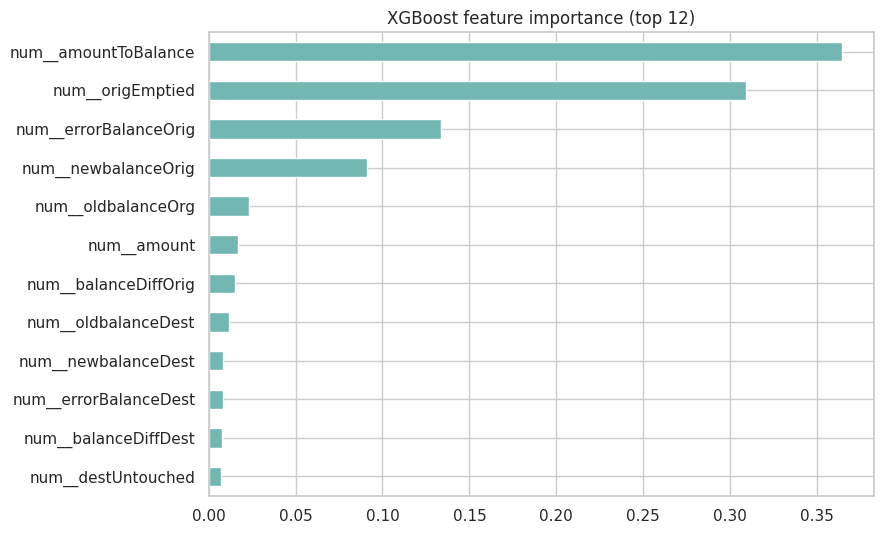

In [54]:
xgb_names = xgb_pipe.named_steps["prep"].get_feature_names_out()
xgb_imp = pd.Series(xgb_pipe.named_steps["clf"].feature_importances_, index=xgb_names).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
xgb_imp.tail(12).plot.barh(ax=ax, color="#72b7b2")
ax.set_title("XGBoost feature importance (top 12)")
plt.tight_layout()
plt.show()

Interpret the comparison on **PR-AUC and recall at a stated precision**, not on accuracy. If the tree models are only marginally better, the interpretable Logistic Regression is a defensible production choice (transparent, fast, easy to audit for a regulated payments setting). If they are far better, say so honestly and treat Logistic Regression as the baseline.

## 20. Ablation: do the engineered features help?

We train the same balanced Logistic Regression on **raw features only** and compare it with the full feature set. This tests the claim 'feature engineering improves the model' with data rather than assuming it.

In [55]:
raw_cols = RAW_NUM + CAT_FEATURES
raw_pipe = make_lr(num_cols=RAW_NUM, cat_cols=CAT_FEATURES).fit(X_train[raw_cols], y_train)
raw_proba = raw_pipe.predict_proba(X_test[raw_cols])[:, 1]

ablation = pd.DataFrame([
    evaluate("LogReg: raw features only", y_test, raw_proba, 0.5),
    evaluate("LogReg: raw + engineered", y_test, proba_lr, 0.5),
]).set_index("model")
ablation[["precision", "recall", "f1", "mcc", "pr_auc", "roc_auc", "tp", "fp", "fn"]]

,precision,recall,f1,mcc,pr_auc,roc_auc,tp,fp,fn
model,,,,,,,,,
LogReg: raw features only,0.0085,0.7021,0.0168,0.0711,0.2345,0.9295,33,3852,14
LogReg: raw + engineered,0.0063,0.8936,0.0125,0.0680,0.4923,0.9247,42,6624,5


In [56]:
delta = ablation.loc["LogReg: raw + engineered", ["precision", "recall", "f1", "pr_auc"]] \
        - ablation.loc["LogReg: raw features only", ["precision", "recall", "f1", "pr_auc"]]
print("Change from adding engineered features (positive = better):")
delta.to_frame("delta").T

Change from adding engineered features (positive = better):


,precision,recall,f1,pr_auc
delta,-0.0022,0.1915,-0.0043,0.2577


Report whichever way this comes out. A large PR-AUC / precision gain supports the feature-engineering claim; a small one means the signal was already in the raw columns for this model.

## 21. Error analysis

Looking at the individual mistakes of the final model (at the tuned threshold) shows what it still gets wrong.

In [57]:
test_view = X_test.copy()
test_view["isFraud"] = np.asarray(y_test)
test_view["fraud_proba"] = proba_lr
test_view["pred"] = pred_tuned

false_neg = test_view[(test_view["isFraud"] == 1) & (test_view["pred"] == 0)]
false_pos = test_view[(test_view["isFraud"] == 0) & (test_view["pred"] == 1)]
print(f"False negatives (missed fraud): {len(false_neg):,}")
print(f"False positives (false alarms): {len(false_pos):,}")

False negatives (missed fraud): 21
False positives (false alarms): 8


In [58]:
cols = ["type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "fraud_proba"]
print("Missed fraud: the 10 lowest-scoring cases")
display(false_neg.sort_values("fraud_proba")[cols].head(10))
print("False alarms: the 10 highest-scoring cases")
display(false_pos.sort_values("fraud_proba", ascending=False)[cols].head(10))

Missed fraud: the 10 lowest-scoring cases


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,fraud_proba
222,CASH_OUT,"416,001.3300",0.0000,0.0000,102.0000,"9,291,619.6200",0.0005
128759,CASH_OUT,"39,713.2800",0.0000,0.0000,"1,274,866.5100","1,314,579.7900",0.0297
69558,CASH_OUT,"149,668.6600",0.0000,0.0000,"44,170.1100","193,838.7600",0.0338
551,CASH_OUT,"132,842.6400","4,499.0800",0.0000,0.0000,"132,842.6400",0.0590
23083,TRANSFER,"994,453.2000","1,437,370.8700","442,917.6700","194,812.7600","665,743.6700",0.1967
11095,CASH_OUT,"43,092.0000","43,092.0000",0.0000,"660,641.7400","1,158,662.9000",0.6643
12367,CASH_OUT,"11,308.0000","11,308.0000",0.0000,0.0000,"302,550.5600",0.6753
131136,CASH_OUT,170.0000,170.0000,0.0000,"413,421.3600","345,764.1500",0.6998
7510,CASH_OUT,"1,996.1700","1,996.1700",0.0000,"2,559.7400","4,555.9200",0.7002
124,CASH_OUT,"2,806.0000","2,806.0000",0.0000,"26,202.0000",0.0000,0.7032


False alarms: the 10 highest-scoring cases


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,fraud_proba
52554,TRANSFER,"2,485,394.4400","2,400,090.0400",0.0000,"2,842,434.3700","5,973,293.2800",0.9986
204394,TRANSFER,"684,753.4300","398,347.0000",0.0000,0.0000,0.0000,0.9961
11448,TRANSFER,"1,954,359.4200","1,836,964.1800",0.0000,"2,526,131.0000","4,480,490.4200",0.9960
38339,TRANSFER,"2,685,146.3900","1,679,141.1200",0.0000,"2,882,613.0200","5,952,600.8000",0.9931
37025,TRANSFER,"1,826,417.8400","1,683,503.7100",0.0000,"2,459,454.8000","5,019,066.8300",0.9916
73368,TRANSFER,"221,728.2500","126,802.0000",0.0000,0.0000,0.0000,0.9897
160376,TRANSFER,"353,946.3900","160,123.9900",0.0000,0.0000,0.0000,0.9896
65588,CASH_OUT,"261,702.9300","262,822.0000","1,119.0700",0.0000,0.0000,0.9880


In [59]:
fn_profile = pd.DataFrame({
    "missed fraud": false_neg[["origEmptied", "destUntouched", "amountToBalance"]].mean(),
    "caught fraud": test_view[(test_view["isFraud"] == 1) & (test_view["pred"] == 1)]
                    [["origEmptied", "destUntouched", "amountToBalance"]].mean(),
    "false alarms": false_pos[["origEmptied", "destUntouched", "amountToBalance"]].mean(),
})
print("Average engineered-feature values by outcome:")
display(fn_profile)
print("Missed fraud by transaction type:")
display(false_neg["type"].value_counts().to_frame("count"))

Average engineered-feature values by outcome:


,missed fraud,caught fraud,false alarms
origEmptied,0.8095,1.0000,0.8750
destUntouched,0.0000,0.8462,0.5000
amountToBalance,2.6992,0.9999,1.4322


Missed fraud by transaction type:


,count
type,
CASH_OUT,20
TRANSFER,1


The profile table shows which fraud patterns slip through (typically transactions that do not match the dominant 'drain the account' pattern) and what legitimate behaviour triggers false alarms. These are the places to look first when improving the model (e.g. interaction features, account history, time-of-day).

## 22. Save the pipeline and verify the reload

The pickle holds the whole fitted pipeline (scaler + encoder + classifier), so the app only has to compute the engineered features and call `predict_proba`. The JSON file stores the expected input columns, the tuned decision threshold and the test metrics so the app and README stay consistent with this notebook.

In [60]:
def to_py(d):
    out = {}
    for k, v in d.items():
        if isinstance(v, (np.floating, float)):
            out[k] = float(v)
        elif isinstance(v, (np.integer, int)):
            out[k] = int(v)
        else:
            out[k] = v
    return out


joblib.dump(lr_pipe, MODEL_PATH, compress=3)

metadata = {
    "model": "Pipeline(ColumnTransformer[StandardScaler, OneHotEncoder] -> LogisticRegression(class_weight='balanced'))",
    "input_columns": NUM_FEATURES + CAT_FEATURES,
    "numeric_features": NUM_FEATURES,
    "categorical_features": CAT_FEATURES,
    "fraud_types": FRAUD_TYPES,
    "threshold": tuned_threshold,
    "default_threshold": 0.5,
    "test_metrics_tuned_threshold": to_py(res_lr_tuned),
    "test_metrics_default_threshold": to_py(res_lr_05),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "fraud_rate_modelling_subset": float(y.mean()),
    "random_state": RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
}
with open(META_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved {MODEL_PATH} and {META_PATH}")

Saved fraud_detection_pipeline.pkl and model_metadata.json


In [61]:
# Reload from disk and confirm identical predictions
reloaded = joblib.load(MODEL_PATH)
sample_rows = X_test.sample(2_000, random_state=RANDOM_STATE) if len(X_test) >= 2_000 else X_test
assert np.allclose(lr_pipe.predict_proba(sample_rows)[:, 1],
                   reloaded.predict_proba(sample_rows)[:, 1]), "Reloaded model differs!"
print("Reload check passed: predictions match.")

# End-to-end scoring of two hand-made transactions, exactly as the app does it
demo = pd.DataFrame([
    {"type": "TRANSFER", "amount": 181.0, "oldbalanceOrg": 181.0, "newbalanceOrig": 0.0,
     "oldbalanceDest": 0.0, "newbalanceDest": 0.0},
    {"type": "CASH_OUT", "amount": 5_000.0, "oldbalanceOrg": 120_000.0, "newbalanceOrig": 115_000.0,
     "oldbalanceDest": 30_000.0, "newbalanceDest": 35_000.0},
])
demo_proba = reloaded.predict_proba(add_features(demo)[NUM_FEATURES + CAT_FEATURES])[:, 1]
demo["fraud_probability"] = demo_proba
demo["alert"] = demo_proba >= tuned_threshold
demo

Reload check passed: predictions match.


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,fraud_probability,alert
0,TRANSFER,181.0000,181.0000,0.0000,0.0000,0.0000,0.9880,True
1,CASH_OUT,"5,000.0000","120,000.0000","115,000.0000","30,000.0000","35,000.0000",0.3620,False


## 23. Summary and README snippet

In [62]:
r = res_lr_tuned
imp = impact[f"LogReg @{tuned_threshold:.3f}"]
print("=" * 62)
print("FINAL MODEL: balanced Logistic Regression pipeline")
print("=" * 62)
print(f"Rows modelled (TRANSFER + CASH_OUT) : {len(data):,} ({y.mean():.3%} fraud)")
print(f"Train / test rows                   : {len(X_train):,} / {len(X_test):,}")
print(f"Decision threshold (val-tuned)      : {tuned_threshold:.4f}")
print(f"Test recall                         : {r['recall']:.2%}")
print(f"Test precision                      : {r['precision']:.2%}")
print(f"Test F1                             : {r['f1']:.4f}")
print(f"Test PR-AUC                         : {r['pr_auc']:.4f}")
print(f"Test ROC-AUC                        : {r['roc_auc']:.4f}")
print(f"Fraud value stopped                 : {imp['value recall %']:.1f}%")
print(f"Alerts raised                       : {imp['% of all transactions alerted']:.3f}% of transactions")
print("=" * 62)

FINAL MODEL: balanced Logistic Regression pipeline
Rows modelled (TRANSFER + CASH_OUT) : 230,708 (0.101% fraud)
Train / test rows                   : 184,565 / 46,142
Decision threshold (val-tuned)      : 0.9878
Test recall                         : 55.32%
Test precision                      : 76.47%
Test F1                             : 0.6420
Test PR-AUC                         : 0.4923
Test ROC-AUC                        : 0.9247
Fraud value stopped                 : 87.2%
Alerts raised                       : 0.074% of transactions


In [63]:
# Markdown table you can paste into README.md ("Model Performance")
rows = [("Majority-class dummy", res_dummy), ("LogReg, no class weights @0.5", res_plain),
        ("LogReg balanced @0.5", res_lr_05), (f"LogReg balanced @{tuned_threshold:.3f} (final)", res_lr_tuned),
        ("Random Forest @0.5", res_rf), ("XGBoost @0.5", res_xgb)]
lines = ["| Model | Precision | Recall | F1 | PR-AUC | ROC-AUC |", "|---|---|---|---|---|---|"]
for name, m in rows:
    lines.append(f"| {name} | {m['precision']:.3f} | {m['recall']:.3f} | {m['f1']:.3f} | "
                 f"{m['pr_auc']:.3f} | {m['roc_auc']:.3f} |")
print("\n".join(lines))

| Model | Precision | Recall | F1 | PR-AUC | ROC-AUC |
|---|---|---|---|---|---|
| Majority-class dummy | 0.000 | 0.000 | 0.000 | 0.001 | 0.500 |
| LogReg, no class weights @0.5 | 0.900 | 0.383 | 0.537 | 0.547 | 0.938 |
| LogReg balanced @0.5 | 0.006 | 0.894 | 0.013 | 0.492 | 0.925 |
| LogReg balanced @0.988 (final) | 0.765 | 0.553 | 0.642 | 0.492 | 0.925 |
| Random Forest @0.5 | 1.000 | 0.894 | 0.944 | 0.897 | 0.961 |
| XGBoost @0.5 | 0.824 | 0.894 | 0.857 | 0.871 | 0.960 |


### Conclusions
* Fraud in this data is concentrated in `TRANSFER` and `CASH_OUT`; restricting to those types keeps all fraud and removes more than half the rows.
* The data is extremely imbalanced, so accuracy is meaningless. The model is judged on recall, precision, PR-AUC and fraud *value* stopped.
* A class-weighted Logistic Regression inside a single Scikit-Learn pipeline gives an interpretable, fast scorer; the threshold is tuned on validation data, never on test.
* The pipeline is serialised with Joblib and served by `streamlit_app.py`.

### Limitations (worth stating in an interview)
* PaySim is **simulated** data with a simple fraud pattern; real-world fraud is adversarial and drifts over time, so these metrics will not transfer one-to-one.
* The split is random, not temporal; a production system should be validated on a time-ordered split and monitored for drift.
* The Streamlit app is a demonstration scorer with manual input, not a streaming service.

### Possible extensions
Time-of-day and account-history features (velocity, repeat counterparties), probability calibration, cost-sensitive thresholding with real fraud/review costs, SHAP explanations for the tree models, and a temporal validation split.